# E0 on realistic data: duration weights, `m-steps` branch vs PR #267

## Why this notebook

`EventModel.estim_duration_probs` computes the posterior of each interval duration from the joint
law of two consecutive events. It is exact **under the HMP model**: `tests/test_duration_probs.py`
checks it against brute-force enumeration. PR #267 approximates the same quantity by the product
of the two event marginals. On data drawn from the model itself, the exact method wins by
construction. Such a test cannot tell whether it stays better when the data do not follow the
model, as with real EEG.

Here the data are generated with the protocol of `docs/source/TPRPPV/`
(`PS_distributions_server.py`), which is independent of the HMP model:

| | data drawn from the HMP model | this notebook (TPRPPV protocol) |
|---|---|---|
| signal | half-sine added to the components | MNE cortical sources projected onto 59 EEG electrodes (forward model) |
| noise | white, independent | coloured MNE sensor noise (IIR filter), then `hmp` PCA + whitening |
| durations | discrete pmf of the model (truncated at the location) | continuous scipy law **shifted** by 50 ms (`loc`), rounded to the sample |
| stage means | fixed | drawn at random, U(1, 500) + 50 ms |
| parameters used | true generator parameters | (a) "true" parameters rebuilt as in TPRPPV, (b) parameters **estimated by EM** |

The HMP model is therefore misspecified on the exact shape of the durations, as it would be on
real data. Both methods receive exactly the same data and the same parameters: only the way the
weights are computed changes.

## Notation

* $i$: trial ($N$ trials); $T_i$: number of samples of trial $i$;
* $e$: event ($n = 3$ events); $j$: interval ($j = 0, \dots, n$); interval $j$ runs from event $j-1$ to event $j$;
* $d$: duration of an interval, in samples; $d^{\text{true}}_{ij}$: simulated duration of interval $j$ in trial $i$;
* $a$: shape parameter of the duration law; $\theta$: scale parameter;
* $w_i(j, d) = P(d_j = d \mid \text{data of trial } i)$: weights computed by
  `EventModel.estim_duration_probs` ("joint") or by `estim_d_probs` from PR #267 ("pr267").

Only **internal** intervals ($1 \le j \le n-1$) are compared: for $j = 0$ and $j = n$ both methods
read the same single-event marginal and return the same result.

## Criteria

For each dataset and each internal interval $j$, averaged over trials $i$:

1. **Log score** $\frac1N \sum_i \log w_i(j, d^{\text{true}}_{ij})$ (higher is better). It is a proper scoring rule: it rewards the probability placed on the true duration.
2. **Absolute error of the posterior mean** $\frac1N \sum_i \left| \sum_d d\, w_i(j,d) - d^{\text{true}}_{ij} \right|$, in samples.
3. **Forbidden mass** $\frac1N \sum_i \sum_{d < \text{location}} w_i(j, d)$: probability placed on durations that the model's prior excludes.
4. **M-step statistics**: for $f(d) \in \{d, \log d, 1/d, d^{1.5}\}$, relative error
   $\left(\frac1N\sum_i \sum_d f(d)\, w_i(j,d) - \frac1N\sum_i f(d^{\text{true}}_{ij})\right) / \frac1N\sum_i f(d^{\text{true}}_{ij})$.
   These are the quantities that exact Weibull, Wald and Lognormal M-steps need.
   Convention: $f(0)$ counts as 0 for $\log d$ and $1/d$ (mass at $d = 0$ shows up in criterion 3).

Part 4 measures run times: `estim_probs` on `devel`, `estim_probs` and `estim_duration_probs` on
the branch, and the PR #267 method.

## 0. Setup

The conda `base` environment holds an editable install of **another** clone (`ML/hmp`): launched
from this folder, `import hmp` would load that version, which has no `estim_duration_probs`. We
therefore put the `hmp-ML` root first on `sys.path`, then check.

In [1]:
import os
import sys
from pathlib import Path

def find_repo_root(start):
    for folder in [start, *start.parents]:
        if (folder / "hmp" / "models" / "event.py").exists() and (folder / "pyproject.toml").exists():
            return folder
    raise RuntimeError("hmp-ML root not found: run the notebook from inside the repository "
                       "or set the HMP_ML_ROOT environment variable.")

REPO = Path(os.environ.get("HMP_ML_ROOT", "")) if os.environ.get("HMP_ML_ROOT") else find_repo_root(Path.cwd())
sys.path.insert(0, str(REPO))

import hmp
from hmp.models import EventModel

assert Path(hmp.__file__).resolve().is_relative_to(REPO.resolve()), f"wrong hmp imported: {hmp.__file__}"
assert hasattr(EventModel, "estim_duration_probs"), "this version of hmp has no estim_duration_probs"
print("hmp imported from", hmp.__file__)

hmp imported from c:\Users\afvry\OneDrive\Documents\ML\hmp-ML\hmp\__init__.py


In [2]:
import importlib.util
import subprocess
import time
import timeit
import warnings

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.stats import gamma as sp_gamma
from scipy.stats import invgauss as sp_invgauss
from scipy.stats import weibull_min as sp_weibull

from hmp import simulations
from hmp.distributions import Gamma, Wald, Weibull

warnings.filterwarnings("ignore")
mne.set_log_level("error")
pd.set_option("display.width", 160)

### Parameters

Taken from `PS_distributions_server.py`: 3 events, 100 trials, 100 Hz, 5 PCA components, 50 ms
location for the internal intervals, same candidate sources and same 9 laws.

Deliberate differences:

* **lower amplitudes**: TPRPPV uses $3 \cdot 10^{-7}$. A pilot run showed that already at
  $5 \cdot 10^{-8}$ the posterior mean of each duration lies on average 0.08 samples from the
  truth: events are located without uncertainty, both weights coincide and the test discriminates
  nothing. Differences appear around $1$ to $2 \cdot 10^{-8}$. Below that ($5 \cdot 10^{-9}$), the
  fitted model itself is off by 15 to 20 samples and the comparison becomes meaningless.
  $5 \cdot 10^{-8}$ is kept as a high-signal reference;
* **5 s epoching window** instead of the 2 s default, so that long trials are not lost. TPRPPV
  discards any simulation where a trial is lost; we keep the same rule, but it now rarely fires.

`N_ITERATIONS` sets the number of datasets per (law, amplitude) pair. Simulations are cached in
`simulated/` and per-dataset results in `benchmark_results/rows/`: re-running the notebook resumes
where it stopped.

**Run time**: the MNE simulation dominates, about 110 s per dataset on this machine; EM and weights
take less than 2 s. With the settings below (9 laws × 3 amplitudes × 3 iterations = 81 datasets),
the first pass took 2 h 33 min (9157 s); later passes take a few minutes.

In [3]:
N_ITERATIONS = 3                      # datasets per (law, amplitude)
AMPLITUDES = [1e-8, 2e-8, 5e-8]       # TPRPPV: 3e-7, where both methods coincide
DISTRIBUTIONS = [("gamma", 2), ("gamma", 3), ("gamma", 4),
                 ("weibull", 2), ("weibull", 3), ("weibull", 4),
                 ("wald", 0.25), ("wald", 0.5), ("wald", 1)]

N_EVENTS = 3
N_TRIALS = 100
SFREQ = 100
N_COMP = 5
FREQUENCY = 10.0                      # 50 ms half-sine
LOC_MS = 50
LOCATIONS_MS = np.array([0] + [LOC_MS] * (N_EVENTS - 1) + [0])
SOURCE_INDEX = [44, 42, 14, 17]
EPOCH_TMAX = 5.0                      # seconds
N_JOBS_MNE = 4                        # MNE threads for the simulation (about 25 % faster)

HERE = Path.cwd()
SIM_DIR = HERE / "simulated"
RES_DIR = HERE / "benchmark_results"
(RES_DIR / "rows").mkdir(parents=True, exist_ok=True)
SIM_DIR.mkdir(exist_ok=True)
print("simulations:", SIM_DIR, "\nresults    :", RES_DIR)

simulations: c:\Users\afvry\OneDrive\Documents\ML\hmp-ML\experiments\estim_d_probs\simulated 
results    : c:\Users\afvry\OneDrive\Documents\ML\hmp-ML\experiments\estim_d_probs\benchmark_results


## 1. Functions

### PR #267 weights

Unmodified copy of `EventModel.estim_d_probs` from PR #267, written as a standalone function so
that it can run on the branch, where that method does not exist.

For an internal interval $j$ it computes
$\sum_t P(\text{event } j-1 \text{ at } t \mid \text{data})\, P(\text{event } j \text{ at } t+d \mid \text{data})$,
the product of the two marginals, then renormalises.

In [4]:
def estim_d_probs_pr267(durations, eventprobs):
    max_duration = np.max(durations)
    n_events = eventprobs.shape[-1]
    n_intervals = n_events + 1
    pmf_post = np.zeros([len(durations), max_duration, n_intervals], dtype=np.float64)
    for interval in range(n_intervals):
        for trial, T in enumerate(durations):
            ponset = eventprobs[trial, :, (interval - 1) if interval > 0 else interval]
            if interval == 0:
                didx = np.arange(T)
                pmf_post[trial, didx, interval] = ponset[didx]
            elif interval == n_intervals - 1:
                didx = np.arange(T)
                pmf_post[trial, didx, interval] = ponset[T - didx - 1]
            else:
                ponset2 = eventprobs[trial, :, interval]
                for end_idx in range(T):
                    didx = np.arange(end_idx, -1, -1)
                    pmf_post[trial, didx, interval] += ponset2[end_idx] * ponset[:end_idx + 1]
            pmf_post[trial, :, interval] /= np.sum(pmf_post[trial, :, interval])
    return pmf_post

### Simulation (TPRPPV protocol)

For a given iteration, the random generator is seeded with the iteration number: sources and stage
means are therefore the same for all 9 laws, as in `PS_distributions_server.py`. For stage $j$ with
mean $m_j$ (ms), the scipy law has shape $a$, scale $\theta_j$ = `mean_to_scale`$(m_j - \text{location}_j)$,
and is shifted by $\text{location}_j$.

`simulations.simulated_times_and_parameters` then returns:

* `true_d`: the simulated durations $d^{\text{true}}_{ij}$, in samples, of shape $(N, n+1)$;
* the "true" time parameters (shape $a$, scale derived from the empirical mean of the durations);
* the "true" channel parameters: mean of the data correlated at the true peak times.

We check that $T_i - 1 = \sum_j d^{\text{true}}_{ij}$ for every trial: this is the model's
convention, where the stimulus is sample 0 and the response sample $T_i - 1$.

In [5]:
def make_distributions(name, a):
    match name:
        case "gamma":
            return Gamma(a), sp_gamma
        case "weibull":
            return Weibull(a), sp_weibull
        case "wald":
            return Wald(a), sp_invgauss
    raise ValueError(name)


def keep_signal(data, montage, events, verbose, preprocessing_kwargs):
    return data, events


def simulate_dataset(dist_name, a, amplitude, iteration):
    with warnings.catch_warnings():       # "file exists", "data was not padded"
        warnings.simplefilter("ignore")
        return _simulate_dataset(dist_name, a, amplitude, iteration)


def _simulate_dataset(dist_name, a, amplitude, iteration):
    rng = np.random.default_rng(seed=iteration)
    names = simulations.available_sources()[rng.choice(SOURCE_INDEX, N_EVENTS + 1)]
    stage_means = rng.uniform(1, 500, N_EVENTS + 1) + LOC_MS
    hmp_dist, sp_dist = make_distributions(dist_name, a)
    scales = [hmp_dist.mean_to_scale(m - LOCATIONS_MS[k]) for k, m in enumerate(stage_means)]
    sources = [[names[k], FREQUENCY, amplitude, sp_dist(a, scale=scales[k], loc=LOCATIONS_MS[k])]
               for k in range(N_EVENTS + 1)]
    fname = f"{dist_name}{a}_{amplitude}_{iteration}_{N_TRIALS}"
    files = simulations.simulate(sources, N_TRIALS, N_JOBS_MNE, fname, path=str(SIM_DIR),
                                 overwrite=False, sfreq=SFREQ, seed=iteration)
    events = np.load(files[0][1])
    resp_trigger = int(np.max(events[:, 2]))
    epoch_data, _ = hmp.io.read_mne_raw(
        [files[0][0]], centering_id={"stimulus/0": 1}, event_id={"response/0": resp_trigger},
        events_provided=[events], montage=simulations.sim_info().get_montage(),
        preprocessing_fn=keep_signal, verbose=False,
        epoching_kwargs={"tmin": -0.2, "tmax": EPOCH_TMAX, "baseline": (None, 0)})
    n_lost = int(np.sum(np.isnan(epoch_data.response_time.values)))
    if n_lost:
        return None, f"{n_lost} trial(s) lost"
    base = hmp.basedata.default(epoch_data, n_comp=N_COMP, duration_id="response_time", verbose=False)
    pdata = hmp.patterndata.PatternData.from_basedata(base)
    model = EventModel(n_events=N_EVENTS, distribution=hmp_dist)
    true_d, true_tpars, true_cpars, _ = simulations.simulated_times_and_parameters(events, model, pdata)
    assert np.array_equal(pdata.durations.values - 1, true_d.sum(axis=1)), "misaligned durations"
    return dict(pdata=pdata, model=model, true_d=true_d,
                true_tpars=np.asarray(true_tpars, dtype=float),
                true_cpars=np.asarray(true_cpars, dtype=float)), None

### "Fitted" parameters

The TPRPPV true parameters are not those of a fit: the scale comes from the empirical mean of the
durations, whereas the model truncates the law at the location instead of shifting it. To match
real use, we also fit an `EventModel` by EM, with the same law as the generator.

EM starts from the true parameters. This avoids event permutations and poor local optima, which
would distort the comparison with $d^{\text{true}}$ for reasons unrelated to how the weights are
computed. The resulting parameters are the ones that maximise the likelihood, not the generator's.

In [6]:
def fit_parameters(sim):
    model = EventModel(n_events=N_EVENTS, distribution=sim["model"].distribution)
    model.fit(sim["pdata"], channel_pars=sim["true_cpars"].copy(), time_pars=sim["true_tpars"].copy(),
              verbose=False)
    cpars = np.asarray(model.channel_pars, dtype=float).reshape(N_EVENTS, -1)
    tpars = np.asarray(model.time_pars, dtype=float).reshape(N_EVENTS + 1, 2)
    return cpars, tpars

### Criteria

`evaluate` takes the weights $w_i(j, d)$, of shape $(N, \max_i T_i, n+1)$, and the true durations
$d^{\text{true}}_{ij}$, and returns one row per internal interval $j$.

In [7]:
LOC_SAMPLES = (LOCATIONS_MS * SFREQ / 1000).astype(int)


def f_log(d):
    return np.where(d > 0, np.log(np.maximum(d, 1)), 0.0)


def f_inv(d):
    return np.where(d > 0, 1 / np.maximum(d, 1), 0.0)


STATISTICS = {"E[d]": lambda d: d, "E[log d]": f_log, "E[1/d]": f_inv, "E[d^1.5]": lambda d: d ** 1.5}


def evaluate(weights, true_d):
    n_trials, n_durations, n_intervals = weights.shape
    d = np.arange(n_durations, dtype=float)
    rows = []
    for j in range(1, n_intervals - 1):
        w = weights[:, :, j]
        d_true = true_d[:, j]
        p_true = w[np.arange(n_trials), np.minimum(d_true, n_durations - 1)]
        row = dict(interval=j,
                   log_score=np.mean(np.log(np.maximum(p_true, 1e-12))),
                   mae=np.mean(np.abs(w @ d - d_true)),
                   forbidden_mass=np.mean(w[:, :LOC_SAMPLES[j]].sum(axis=1)))
        for name, f in STATISTICS.items():
            truth = np.mean(f(d_true.astype(float)))
            row[f"rel_err {name}"] = (np.mean(w @ f(d)) - truth) / truth
        rows.append(row)
    return rows

## 2. Main loop

For each generating law, amplitude and iteration: simulation, then, for each parameter set
(`true` or `fitted`), both weights and the criteria. The rows of each dataset are saved to
`benchmark_results/rows/<dataset>.csv`; a dataset already processed is read back instead of being
recomputed. Datasets dropped because a trial was lost have no file and are re-checked (from the
cached simulation, in a few seconds) on every run.

In [8]:
def run_one(dist_name, a, amplitude, iteration):
    sim, problem = simulate_dataset(dist_name, a, amplitude, iteration)
    if sim is None:
        return [], problem
    pdata, model, true_d = sim["pdata"], sim["model"], sim["true_d"]
    rows = []
    param_sets = {"true": (sim["true_cpars"], sim["true_tpars"])}
    try:
        param_sets["fitted"] = fit_parameters(sim)
    except Exception as err:          # an EM failure must not stop the benchmark
        problem = f"EM: {err!r}"
    for params_name, (cpars, tpars) in param_sets.items():
        _, eventprobs, _ = model.estim_probs(pdata, cpars, tpars)
        weights = {"joint": model.estim_duration_probs(pdata, cpars, tpars),
                   "pr267": estim_d_probs_pr267(pdata.durations.values, eventprobs)}
        for method, w in weights.items():
            for row in evaluate(w, true_d):
                rows.append(dict(distribution=f"{dist_name.capitalize()} {a}", amplitude=amplitude,
                                 iteration=iteration, params=params_name, method=method,
                                 mean_rt_ms=10 * pdata.durations.values.mean(), **row))
    return rows, problem


t_start = time.perf_counter()
problems = []
for amplitude in AMPLITUDES:
    for dist_name, a in DISTRIBUTIONS:
        for iteration in range(N_ITERATIONS):
            key = f"{dist_name}{a}_{amplitude}_{iteration}"
            path = RES_DIR / "rows" / f"{key}.csv"
            if path.exists():
                continue
            rows, problem = run_one(dist_name, a, amplitude, iteration)
            if problem:
                problems.append((key, problem))
            if rows:
                pd.DataFrame(rows).to_csv(path, index=False)
            print(f"{key:<28} {'ok' if rows else 'dropped'} {problem or ''}  "
                  f"({time.perf_counter() - t_start:.0f} s)")

wanted = {f"{n}{a}_{amp}_{it}" for amp in AMPLITUDES for n, a in DISTRIBUTIONS for it in range(N_ITERATIONS)}
df = pd.concat([pd.read_csv(p) for p in sorted((RES_DIR / "rows").glob("*.csv")) if p.stem in wanted],
               ignore_index=True)
print(f"\n{df.groupby(['distribution', 'amplitude', 'iteration']).ngroups} datasets, "
      f"{len(df)} rows; problems: {problems or 'none'}")

wald1_1e-08_1                dropped 1 trial(s) lost  (2 s)
wald1_2e-08_1                dropped 1 trial(s) lost  (3 s)
wald1_5e-08_1                dropped 1 trial(s) lost  (5 s)

78 datasets, 624 rows; problems: [('wald1_1e-08_1', '1 trial(s) lost'), ('wald1_2e-08_1', '1 trial(s) lost'), ('wald1_5e-08_1', '1 trial(s) lost')]


## 3. Results

### 3.1 Overview

Mean ± standard error over datasets and the two internal intervals. The log score is in nats per
trial; the absolute error is in samples (10 ms); the forbidden mass is a probability.

In [9]:
def mean_sem(s):
    return f"{s.mean():.3f} ± {s.sem():.3f}"

overview = (df.groupby(["params", "amplitude", "method"])[["log_score", "mae", "forbidden_mass"]]
              .agg(mean_sem).unstack("method"))
overview

log_score                             mae                 forbidden_mass               
method                        joint           pr267           joint           pr267          joint          pr267
params amplitude                                                                                                 
fitted 1.000000e-08  -3.523 ± 0.131  -3.616 ± 0.121  10.288 ± 0.711  11.074 ± 0.729  0.000 ± 0.000  0.026 ± 0.003
       2.000000e-08  -0.968 ± 0.026  -0.980 ± 0.027   1.592 ± 0.158   1.702 ± 0.166  0.000 ± 0.000  0.007 ± 0.002
       5.000000e-08  -0.132 ± 0.009  -0.132 ± 0.009   0.058 ± 0.003   0.058 ± 0.003  0.000 ± 0.000  0.000 ± 0.000
true   1.000000e-08  -2.757 ± 0.112  -2.925 ± 0.101   6.985 ± 0.670   8.481 ± 0.639  0.000 ± 0.000  0.042 ± 0.006
       2.000000e-08  -0.916 ± 0.023  -0.927 ± 0.024   1.402 ± 0.137   1.501 ± 0.144  0.000 ± 0.000  0.008 ± 0.002
       5.000000e-08  -0.130 ± 0.009  -0.130 ± 0.009   0.059 ± 0.003   0.059 ± 0.003  0.000 ± 0.000  0.000 ± 0.000

### 3.2 Paired comparison

For each dataset, interval and parameter set, we compute the difference joint − pr267 for the log
score (positive = joint better) and pr267 − joint for the absolute error (positive = joint better),
and count the share of cases where the joint method wins. Pairing removes the variability between
datasets: only the effect of the method remains. When the mean difference is of order $10^{-4}$ or
less, the share of wins only reflects rounding-level noise.

In [10]:
keys = ["distribution", "amplitude", "iteration", "params", "interval"]
wide = df.pivot_table(index=keys, columns="method", values=["log_score", "mae", "forbidden_mass"])
paired = pd.DataFrame({
    "Δ log_score (joint − pr267)": wide[("log_score", "joint")] - wide[("log_score", "pr267")],
    "Δ mae (pr267 − joint)": wide[("mae", "pr267")] - wide[("mae", "joint")],
}).reset_index()
summary = paired.groupby(["params", "amplitude"]).agg(
    n=("Δ log_score (joint − pr267)", "size"),
    delta_log_score=("Δ log_score (joint − pr267)", "mean"),
    joint_better_log_score=("Δ log_score (joint − pr267)", lambda s: f"{100 * (s > 0).mean():.0f} %"),
    delta_mae=("Δ mae (pr267 − joint)", "mean"),
    joint_better_mae=("Δ mae (pr267 − joint)", lambda s: f"{100 * (s > 0).mean():.0f} %"),
)
summary.style.format({"delta_log_score": "{:.2e}", "delta_mae": "{:.2e}"})

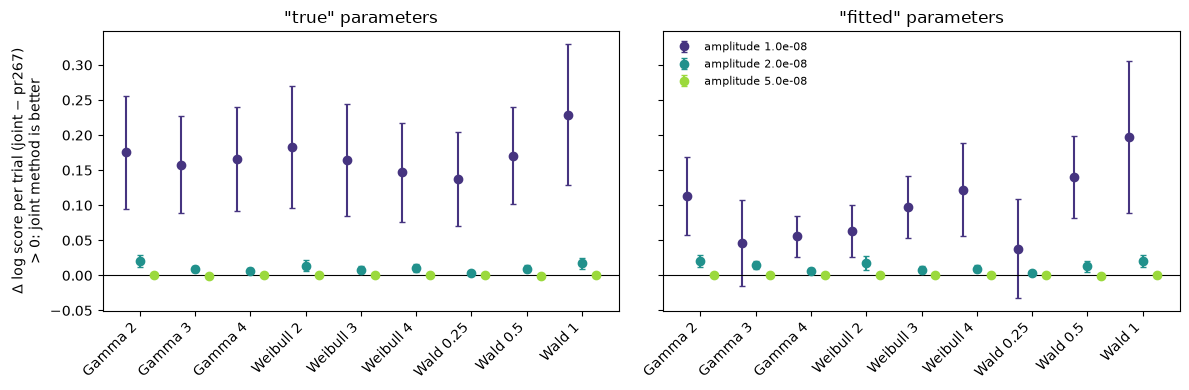

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
dists = [f"{n.capitalize()} {a}" for n, a in DISTRIBUTIONS]
colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(AMPLITUDES)))
for ax, params_name in zip(axs, ["true", "fitted"]):
    sub = paired[paired.params == params_name]
    for k, (amp, color) in enumerate(zip(AMPLITUDES, colors)):
        g = sub[sub.amplitude == amp].groupby("distribution")["Δ log_score (joint − pr267)"]
        x = np.arange(len(dists)) + (k - (len(AMPLITUDES) - 1) / 2) * 0.25
        ax.errorbar(x, g.mean().reindex(dists), yerr=g.sem().reindex(dists), fmt="o", color=color,
                    capsize=2, label=f"amplitude {amp:.1e}")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(np.arange(len(dists)), dists, rotation=45, ha="right")
    ax.set_title(f'"{params_name}" parameters')
axs[0].set_ylabel("Δ log score per trial (joint − pr267)\n> 0: joint method is better")
axs[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(RES_DIR / "paired_log_score.png", dpi=150)
plt.show()

### 3.3 M-step statistics

Mean relative error (%) of the weighted statistics with respect to the true durations. This is
the criterion that matters for E1 and E2: a bias here turns directly into a bias on the estimated
shape $a$ and scale $\theta$.

The first table gives the **signed** mean, which shows the direction of the bias but lets errors
of opposite sign (from different intervals or datasets) cancel out.

In [12]:
stat_cols = [f"rel_err {name}" for name in STATISTICS]
long = df.melt(id_vars=keys[:-1] + ["interval", "method"], value_vars=stat_cols,
               var_name="statistic", value_name="rel_err")
long["statistic"] = long["statistic"].str.replace("rel_err ", "")
mstep = (100 * long.groupby(["params", "amplitude", "statistic", "method"]).rel_err.mean()).round(2)
mstep.unstack("method")

method                         joint   pr267
params amplitude    statistic               
fitted 1.000000e-08 E[1/d]     -0.44    6.46
                    E[d]       32.00   43.12
                    E[d^1.5]   77.12  107.35
                    E[log d]    7.46    8.42
       2.000000e-08 E[1/d]      0.46    0.99
                    E[d]        1.68    2.92
                    E[d^1.5]    3.68    6.98
                    E[log d]    0.30    0.44
       5.000000e-08 E[1/d]      0.11    0.11
                    E[d]       -0.03   -0.03
                    E[d^1.5]   -0.02   -0.02
                    E[log d]   -0.04   -0.04
true   1.000000e-08 E[1/d]      4.28   12.48
                    E[d]        4.69   23.65
                    E[d^1.5]   10.63   58.17
                    E[log d]    0.75    3.35
       2.000000e-08 E[1/d]      0.90    1.24
                    E[d]        0.72    1.85
                    E[d^1.5]    1.81    4.80
                    E[log d]   -0.01    0.12
       5.000000e-08 E[1/d]      0.15    0.16
                    E[d]       -0.08   -0.08
                    E[d^1.5]   -0.10   -0.10
                    E[log d]   -0.07   -0.07

The second table removes the cancellation: mean **absolute** relative error (%), and the share of
paired cases (same dataset, interval and parameters) where the joint method is strictly closer to
the truth. Exact ties (both errors equal to $10^{-6}$ %) count as losses, which matters only at the
highest amplitude.

In [13]:
long["abs_rel_err"] = 100 * long.rel_err.abs()
abs_wide = long.pivot_table(index=keys + ["statistic"], columns="method", values="abs_rel_err")
abs_table = abs_wide.groupby(["params", "amplitude", "statistic"]).mean().round(2)
abs_table["joint closer"] = ((abs_wide.joint < abs_wide.pr267 - 1e-6)
                             .groupby(["params", "amplitude", "statistic"]).mean()
                             .map(lambda x: f"{100 * x:.0f} %"))
abs_table

method                         joint   pr267 joint closer
params amplitude    statistic                            
fitted 1.000000e-08 E[1/d]     23.51   27.38         54 %
                    E[d]       41.67   50.17         62 %
                    E[d^1.5]   89.35  116.04         65 %
                    E[log d]   11.58   12.24         62 %
       2.000000e-08 E[1/d]      1.71    2.11         52 %
                    E[d]        2.50    3.62         67 %
                    E[d^1.5]    4.82    7.88         73 %
                    E[log d]    0.70    0.82         46 %
       5.000000e-08 E[1/d]      0.13    0.14         67 %
                    E[d]        0.05    0.05         44 %
                    E[d^1.5]    0.07    0.07         60 %
                    E[log d]    0.04    0.04         62 %
true   1.000000e-08 E[1/d]      7.64   17.63         77 %
                    E[d]        6.26   24.25         73 %
                    E[d^1.5]   12.05   58.89         83 %
                    E[log d]    2.31    5.04         83 %
       2.000000e-08 E[1/d]      1.43    1.74         58 %
                    E[d]        1.56    2.49         62 %
                    E[d^1.5]    2.93    5.59         69 %
                    E[log d]    0.47    0.55         48 %
       5.000000e-08 E[1/d]      0.19    0.19         56 %
                    E[d]        0.11    0.11         31 %
                    E[d^1.5]    0.13    0.13         33 %
                    E[log d]    0.07    0.07         54 %

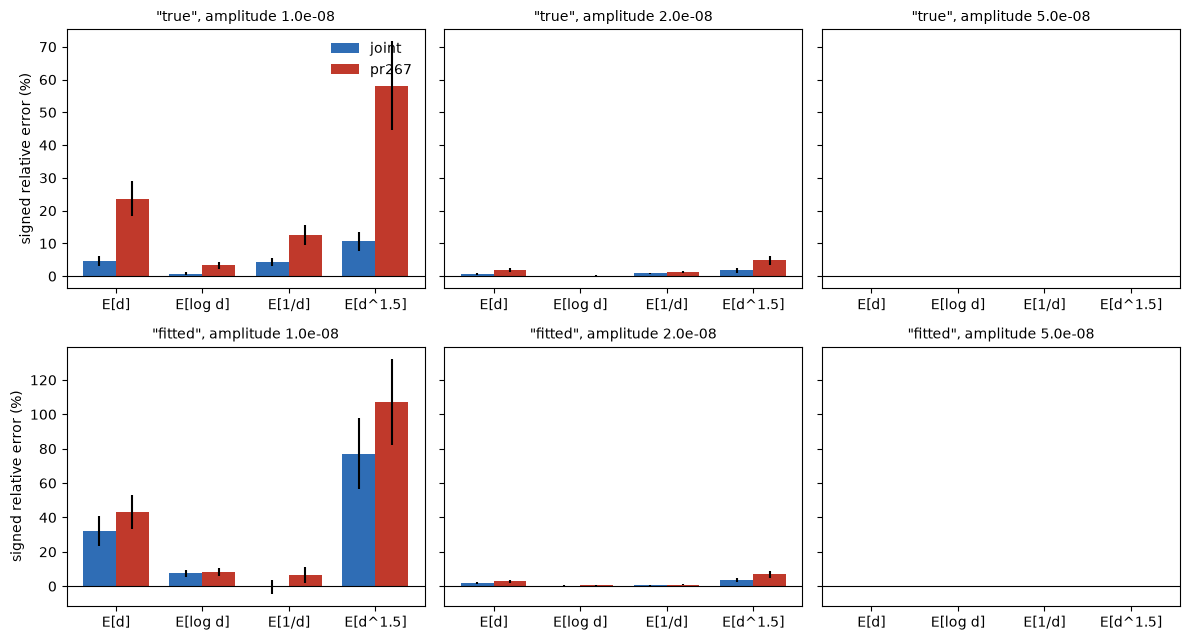

In [14]:
fig, axs = plt.subplots(len(["true", "fitted"]), len(AMPLITUDES), figsize=(4 * len(AMPLITUDES), 6.5),
                        sharey="row", squeeze=False)
names = list(STATISTICS)
for r, params_name in enumerate(["true", "fitted"]):
    for c, amp in enumerate(AMPLITUDES):
        ax = axs[r, c]
        sub = long[(long.params == params_name) & (long.amplitude == amp)]
        for k, (method, color) in enumerate([("joint", "#2f6db5"), ("pr267", "#c0392b")]):
            g = sub[sub.method == method].groupby("statistic").rel_err
            ax.bar(np.arange(len(names)) + (k - 0.5) * 0.38, 100 * g.mean().reindex(names), 0.38,
                   yerr=100 * g.sem().reindex(names), color=color, label=method)
        ax.axhline(0, color="k", lw=0.8)
        ax.set_xticks(np.arange(len(names)), names)
        ax.set_title(f'"{params_name}", amplitude {amp:.1e}', fontsize=10)
    axs[r, 0].set_ylabel("signed relative error (%)")
axs[0, 0].legend(frameon=False)
fig.tight_layout()
fig.savefig(RES_DIR / "mstep_statistics.png", dpi=150)
plt.show()

### 3.4 By generating law

Same criteria, broken down by law and restricted to the lowest amplitude, where the differences
are largest.

In [15]:
low = df[df.amplitude == min(AMPLITUDES)]
(low.groupby(["params", "distribution", "method"])[["log_score", "mae", "forbidden_mass", "rel_err E[1/d]"]]
    .mean().round(3).unstack("method"))

log_score            mae         forbidden_mass        rel_err E[1/d]       
method                  joint  pr267   joint   pr267          joint  pr267          joint  pr267
params distribution                                                                             
fitted Gamma 2         -3.919 -4.032  13.033  14.335            0.0  0.029          0.014  0.097
       Gamma 3         -3.596 -3.641  11.029  11.740            0.0  0.024          0.051  0.120
       Gamma 4         -3.491 -3.546   9.409   9.936            0.0  0.021         -0.103 -0.025
       Wald 0.25       -3.487 -3.525   8.958   9.349            0.0  0.024          0.045  0.100
       Wald 0.5        -3.679 -3.820  12.404  13.764            0.0  0.028          0.013  0.094
       Wald 1          -3.857 -4.054  17.402  18.976            0.0  0.037         -0.065 -0.023
       Weibull 2       -4.159 -4.222  12.487  12.979            0.0  0.022          0.011  0.085
       Weibull 3       -3.123 -3.220   6.172   6.729            0.0  0.027         -0.006  0.072
       Weibull 4       -2.506 -2.628   4.069   4.487            0.0  0.025         -0.018  0.032
true   Gamma 2         -2.965 -3.140   8.952  11.161            0.0  0.048          0.055  0.150
       Gamma 3         -2.856 -3.014   7.619   9.154            0.0  0.049          0.074  0.164
       Gamma 4         -2.778 -2.944   6.018   7.239            0.0  0.047          0.061  0.143
       Wald 0.25       -2.771 -2.909   6.375   7.453            0.0  0.038          0.031  0.117
       Wald 0.5        -2.994 -3.165   9.079  11.363            0.0  0.042          0.031  0.126
       Wald 1          -2.771 -3.000  10.642  13.535            0.0  0.060          0.029  0.137
       Weibull 2       -2.882 -3.066   7.170   8.759            0.0  0.038          0.043  0.125
       Weibull 3       -2.520 -2.684   4.570   5.358            0.0  0.035          0.032  0.096
       Weibull 4       -2.283 -2.430   3.658   3.993            0.0  0.031          0.024  0.070

## 4. Run time

On the same data and the same parameters, we compare:

| name | what is measured |
|---|---|
| `devel estim_probs` | `estim_probs` from `devel`, loaded with `git show devel:hmp/models/event.py` |
| `branch estim_probs` | `estim_probs` on the branch (forward/backward moved into `_forward_backward`) |
| `branch estim_duration_probs` | forward/backward **plus** the joint weights |
| `pr267 total` | `estim_probs` + `estim_d_probs_pr267` (the PR needs the event probabilities) |
| `pr267 weights only` | `estim_d_probs_pr267` alone |

Two separate questions:

1. **Does adding the function slow down the current code?** `fit` does not call
   `estim_duration_probs`: only the change to `estim_probs` matters. We therefore compare
   `estim_probs` and a full `fit` between `devel` and the branch, and check that the results are
   identical.
2. **What would the weights cost in an exact M-step?** `estim_duration_probs` reruns the
   forward/backward pass. Called after `estim_probs` at each iteration, it adds its full time. If a
   future M-step shared the forward/backward pass, the overhead would only be
   `estim_duration_probs − estim_probs`.

`devel` requires an explicit trial mask (`subset_epochs=None` raises a `TypeError` there): we pass
the same boolean mask to both versions.

In [16]:
def load_devel_event_module():
    for ref in ("devel", "origin/devel"):
        result = subprocess.run(["git", "-C", str(REPO), "show", f"{ref}:hmp/models/event.py"],
                                capture_output=True, text=True, encoding="utf-8")
        if result.returncode == 0:
            break
    else:
        raise RuntimeError(result.stderr)
    spec = importlib.util.spec_from_loader("event_devel", loader=None)
    module = importlib.util.module_from_spec(spec)
    exec(compile(result.stdout, f"{ref}:hmp/models/event.py", "exec"), module.__dict__)
    return module


EventModelDevel = load_devel_event_module().EventModel
assert not hasattr(EventModelDevel, "estim_duration_probs")


def median_times(functions, repeat=9):
    # Functions are timed in turn (A, B, C, A, B, C, ...): any drift of the machine (CPU
    # frequency, cache) affects all methods in the same way.
    for fn in functions.values():
        fn()                                          # warm-up
    samples = {name: [] for name in functions}
    for _ in range(repeat):
        for name, fn in functions.items():
            samples[name].append(timeit.timeit(fn, number=1))
    return {name: float(np.median(s)) for name, s in samples.items()}

### 4.1 One call, several datasets

The first iteration of each (law, amplitude) pair is read back from the cache. The problem size is
the total number of samples $\sum_i T_i$.

In [17]:
timing_rows = []
for amplitude in AMPLITUDES:
    for dist_name, a in DISTRIBUTIONS:
        sim, problem = simulate_dataset(dist_name, a, amplitude, 0)
        if sim is None:
            continue
        pdata, cpars, tpars = sim["pdata"], sim["true_cpars"], sim["true_tpars"]
        mask = np.ones(len(pdata.starts), dtype=bool)
        branch = EventModel(n_events=N_EVENTS, distribution=sim["model"].distribution)
        devel = EventModelDevel(n_events=N_EVENTS, distribution=sim["model"].distribution)

        out_devel = devel.estim_probs(pdata, cpars, tpars, subset_epochs=mask)
        out_branch = branch.estim_probs(pdata, cpars, tpars, subset_epochs=mask)
        identical = all(np.array_equal(x, y) for x, y in zip(out_devel, out_branch))
        eventprobs = out_branch[1]
        durations = pdata.durations.values

        t = median_times({
            "devel estim_probs": lambda: devel.estim_probs(pdata, cpars, tpars, subset_epochs=mask),
            "branch estim_probs": lambda: branch.estim_probs(pdata, cpars, tpars, subset_epochs=mask),
            "branch estim_duration_probs":
                lambda: branch.estim_duration_probs(pdata, cpars, tpars, subset_epochs=mask),
            "pr267 weights only": lambda: estim_d_probs_pr267(durations, eventprobs),
        })
        t["pr267 total"] = t["branch estim_probs"] + t["pr267 weights only"]
        timing_rows.append(dict(distribution=f"{dist_name.capitalize()} {a}", amplitude=amplitude,
                                total_samples=int(durations.sum()), max_T=int(durations.max()),
                                estim_probs_identical=identical, **t))

timing = pd.DataFrame(timing_rows)
assert timing.estim_probs_identical.all(), "estim_probs differs between devel and the branch"
timing.to_csv(RES_DIR / "timing_calls.csv", index=False)
cols = ["devel estim_probs", "branch estim_probs", "branch estim_duration_probs",
        "pr267 weights only", "pr267 total"]
print("time per call, in ms, over", len(timing), "datasets")
(1000 * timing[cols]).describe().loc[["mean", "50%", "min", "max"]].round(1).rename(
    index={"50%": "median"})

time per call, in ms, over 27 datasets


,devel estim_probs,branch estim_probs,branch estim_duration_probs,pr267 weights only,pr267 total
mean,30.3,30.0,36.5,190.3,220.4
median,23.1,22.7,29.3,176.1,198.1
min,15.0,15.5,21.0,158.9,187.7
max,101.2,94.4,106.9,282.8,377.2


In [18]:
ratios = pd.DataFrame({
    "branch / devel (estim_probs)": timing["branch estim_probs"] / timing["devel estim_probs"],
    "estim_duration_probs / estim_probs": timing["branch estim_duration_probs"] / timing["branch estim_probs"],
    "pr267 total / estim_duration_probs": timing["pr267 total"] / timing["branch estim_duration_probs"],
})
ratios.describe().loc[["mean", "50%", "min", "max"]].round(2).rename(index={"50%": "median"})

,branch / devel (estim_probs),estim_duration_probs / estim_probs,pr267 total / estim_duration_probs
mean,1.00,1.26,6.73
median,0.99,1.26,7.00
min,0.91,1.06,3.49
max,1.14,1.48,9.14


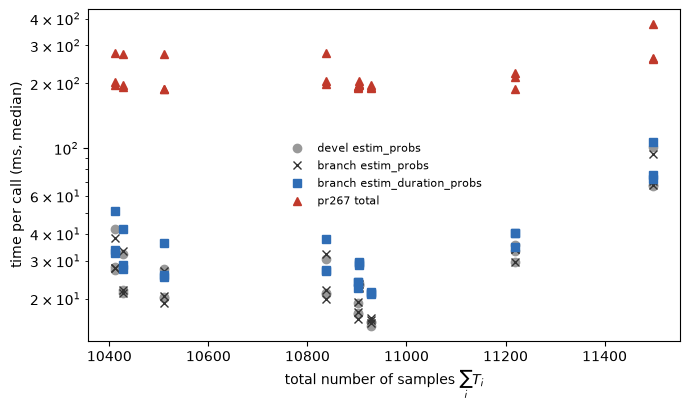

In [19]:
fig, ax = plt.subplots(figsize=(7, 4.2))
styles = {"devel estim_probs": ("#999999", "o"), "branch estim_probs": ("#333333", "x"),
          "branch estim_duration_probs": ("#2f6db5", "s"), "pr267 total": ("#c0392b", "^")}
order = timing.sort_values("total_samples")
for name, (color, marker) in styles.items():
    ax.plot(order.total_samples, 1000 * order[name], marker=marker, ls="", color=color, label=name)
ax.set_xlabel(r"total number of samples $\sum_i T_i$")
ax.set_ylabel("time per call (ms, median)")
ax.set_yscale("log")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(RES_DIR / "timing_calls.png", dpi=150)
plt.show()

### 4.2 Full fit: `devel` vs the branch

Same dataset and same starting point: the default starting point of `fit` (mean duration split
into equal parts, zero contributions), more realistic than the true parameters, from which EM
would converge in one or two iterations. If the refactoring of `estim_probs` is free, run times are
equal up to noise and the estimated parameters are bit-for-bit identical.

In [20]:
fit_rows = []
for amplitude in AMPLITUDES:
    sim, _ = simulate_dataset(*DISTRIBUTIONS[0], amplitude, 0)
    if sim is None:
        continue
    results = {}
    for version, cls in (("devel", EventModelDevel), ("branch", EventModel)):
        times = []
        for _ in range(3):
            model = cls(n_events=N_EVENTS, distribution=sim["model"].distribution)
            t0 = time.perf_counter()
            model.fit(sim["pdata"], verbose=False)
            times.append(time.perf_counter() - t0)
        results[version] = model
        fit_rows.append(dict(amplitude=amplitude, version=version, fit_s=np.median(times),
                             n_iterations=len(model.traces) - 1 if model.traces is not None else np.nan))
    same = (np.array_equal(results["devel"].channel_pars, results["branch"].channel_pars)
            and np.array_equal(results["devel"].time_pars, results["branch"].time_pars))
    fit_rows[-1]["identical_to_devel"] = fit_rows[-2]["identical_to_devel"] = same

fit_timing = pd.DataFrame(fit_rows)
fit_timing.to_csv(RES_DIR / "timing_fit.csv", index=False)
fit_timing.pivot_table(index="amplitude", columns="version",
                       values=["fit_s", "n_iterations", "identical_to_devel"], aggfunc="first")

fit_s           identical_to_devel       n_iterations      
version         branch     devel             branch devel       branch devel
amplitude                                                                   
1.000000e-08  1.166753  1.145259               True  True           33    33
2.000000e-08  2.666138  2.634581               True  True           76    76
5.000000e-08  0.404980  0.402772               True  True           11    11

## 5. Discussion

The figures below come from the run stored in `benchmark_results/`: 81 datasets planned
(9 laws × 3 amplitudes × 3 iterations), 78 kept. The 3 Wald 1 datasets of iteration 1 were dropped
because one trial was longer than the 5 s epoching window. Each dataset gives 2 internal intervals
× 2 parameter sets, i.e. 52 paired cases per (parameter set, amplitude). Timings in part 4 are
re-measured at each run and may differ slightly from the values quoted here.

### 5.1 Does the joint method stay better on data that do not follow the model?

Yes, wherever the two methods differ at all. The size of the gain, however, depends strongly on
the signal-to-noise ratio.

* **High signal ($5 \cdot 10^{-8}$)**: both methods are identical. The posterior mean lies
  0.06 samples from the truth and the log score differs by $4 \cdot 10^{-5}$ nats. Events are
  located without uncertainty, so the product of the marginals is the joint law. The 90–92 % "wins"
  in 3.2 are rounding-level noise.
* **Intermediate signal ($2 \cdot 10^{-8}$)**: small but systematic gain. The log score improves
  by 0.011 nats per trial (true parameters) and 0.012 (fitted), and the joint method wins in 94 %
  of the paired cases. The posterior mean is 0.10 samples closer (about 7 % of an error of
  1.4–1.6 samples), and the joint method wins on this criterion in 77–79 % of cases. PR #267 puts
  0.7–0.8 % of its mass on forbidden durations on average (up to 4.4 % on one interval).
* **Low signal ($10^{-8}$)**: clear gain. The log score improves by 0.17 nats per trial with the
  true parameters, i.e. the joint method puts on average $e^{0.17} \approx 1.18$ times more
  probability on the true duration, and by 0.09 nats with the fitted parameters. The joint method
  wins in 88 % and 77 % of cases. The absolute error drops from 8.5 to 7.0 samples (true) and
  from 11.1 to 10.3 (fitted). PR #267 puts 4.2 % (true) and 2.6 % (fitted) of its mass on
  forbidden durations, up to 16 % on one interval.
* **Across laws** (3.4 shows $10^{-8}$): at $10^{-8}$ and $2 \cdot 10^{-8}$, the joint method has
  the better mean log score and the smaller mean absolute error for each of the 9 generating laws,
  with both parameter sets. The gain is therefore not tied to a particular duration law. At
  $5 \cdot 10^{-8}$, the per-law differences are of order $10^{-4}$ nats in either direction.

### 5.2 M-step statistics

Exact weights are not unbiased weights here. The joint method is exact for the HMP model, but the
data depart from it in three ways: the model truncates the duration law at the location whereas
the generator shifts it, the noise is coloured, and 100 trials leave substantial sampling noise.
The joint method therefore also has a bias with respect to the true durations, and the gap between
the two methods should be read against this error that both share.

* **True parameters, $10^{-8}$**: clear advantage. Mean absolute relative error, joint vs
  pr267: $E[d]$ 6.3 vs 24.3 %, $E[d^{1.5}]$ 12.1 vs 58.9 %, $E[1/d]$ 7.6 vs 17.6 %, $E[\log d]$
  2.3 vs 5.0 %. The joint method is closer to the truth in 73–83 % of cases.
* **True parameters, $2 \cdot 10^{-8}$**: smaller advantage, concentrated on the statistics
  sensitive to long durations. $E[d]$ 1.6 vs 2.5 % and $E[d^{1.5}]$ 2.9 vs 5.6 % (joint closer in
  62–69 % of cases). $E[1/d]$ (1.4 vs 1.7 %) and $E[\log d]$ (0.47 vs 0.55 %) are almost a tie:
  the joint method is closer in only 58 % and 48 % of cases.
* **Fitted parameters, $10^{-8}$**: both methods are strongly biased. The signed bias on $E[d]$
  is +32 % (joint) vs +43 % (pr267), and the absolute error on $E[d^{1.5}]$ is 89 vs 116 %. The
  joint method is closer in only 54–65 % of cases. This bias comes from the parameters estimated by
  EM on a weak, misspecified signal, not from the way the weights are computed. At this amplitude,
  the choice of method is a second-order effect.
* **$5 \cdot 10^{-8}$**: errors below 0.2 % for both methods, identical to the second decimal.

In short, the advantage on the M-step statistics is large only at very low signal with good
parameters. It shrinks to a few percentage points at $2 \cdot 10^{-8}$, mostly on $E[d]$ and
$E[d^{1.5}]$, and becomes small relative to the shared error when the parameters are fitted at
$10^{-8}$. In every cell, the mean absolute error of the joint method is lower than or equal to
that of PR #267.

### 5.3 Run time

Absolute times depend on the load of the machine; the ratios are stable from one run to the next
(two runs gave the same medians to within 0.02 for the first two ratios and 0.06 for the third).

* **The refactoring costs nothing.** `estim_probs` on the branch takes as long as on `devel`
  (median ratio 1.00 to 1.01 ; spread 0.92–1.24 across datasets, i.e. measurement noise), and the
  outputs are identical on all 27 datasets. A full `fit` from the default starting point yields
  bit-for-bit identical parameters with the same number of iterations (33, 76 and 11), in the same
  time up to noise (4.2).
* **Cost of the weights.** `estim_duration_probs` takes about 1.25 times as long as `estim_probs`
  (median 28 vs 23 ms per call in this run). Called in addition to `estim_probs` at each EM
  iteration, it would roughly double the cost of the E-step; sharing the forward/backward pass would
  bring the overhead down to about 25 %.
* **PR #267 is about 7 times slower** than the joint method (median ratio 7.0; 3.3–9.3 across
  datasets): 200 ms vs 28 ms per call in this run, of which 180 ms for the weights alone. Its Python
  loop over trials and end samples has a cost in $O(N\,T^2)$ per interval.

### 5.4 Conclusion

On data generated with the TPRPPV protocol, which is independent of the HMP model, the joint method
is better on average wherever the two methods differ, for each of the 9 laws and both parameter
sets, and it never puts mass on forbidden durations. The gain grows as events become harder to
locate: it is zero at $5 \cdot 10^{-8}$, small but systematic at $2 \cdot 10^{-8}$, and clear at
$10^{-8}$. When the parameters are fitted at low signal, the error shared by both methods (model
misspecification, EM bias) is larger than the gap between them.

**Limits.** 3 datasets per (law, amplitude) cell; the standard errors treat the two intervals of a
dataset as independent, which they are not quite; a single source frequency (10 Hz) and a single
number of events (3); the amplitudes were chosen in the range where the methods differ (at the
TPRPPV amplitude, $3 \cdot 10^{-7}$, they coincide).